# 导入相关数据库和相关函数

In [2]:
# General
import pandas as pd
import numpy as np
import pathlib
import matplotlib.pyplot as plt
%matplotlib inline

# ML
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
import joblib
from xgboost import XGBRegressor 

# Cp 
from cp_app.utils import select_structures_new
from cp_app.descriptors import simple_descriptors, PLMF_477D, PLMF_first_400D, PLMF_first_300D, PLMF_first_200D, PLMF_first_100D, PLMF_first_20D, C_PLUS_PLMF_400D, C_PLUS_PLMF_300D, C_PLUS_PLMF_200D, C_PLUS_PLMF_100D, C_PLUS_PLMF_20D, MP, LEAF,mp1_C_PLMF_100D,mp1_C_PLMF_200D
from cp_app.predictions import predict_G_ensemble_dataset

# others
import warnings
warnings.filterwarnings('ignore')
import shap
import seaborn as sns
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 传入训练数据集

In [4]:
RANDOM_SEED = 3982          #设置固定随机种子，确保每次得到的随机结果一致
DATA_DIR = 'D:/毕设课题学习/毕设课题学习/毕设论文代码和数据集/数据集/训练和测试数据/613个数据中的540个Material Project数据/'#文件夹路径
DATA_ALL = 'alldata.csv'#数据文件名
flag="smallML_432_10" # name_#TrainSize_#EnsembleSize
N_ensemble = int(flag.split("_")[2])#提取出flag中的集成学习模型数量为10个
N_train=int(flag.split("_")[1])     #提取出flag中的训练集数量
df_allsites = pd.read_csv(DATA_DIR+DATA_ALL,encoding='gb2312')#读取所有站点数据,最常用encoding='gb2312'或'utf-8'
print("Total structures: ", len(df_allsites))#显示结构数据集总记录数

Total structures:  540


# 对数据进行划分(随机划分)

In [5]:
inds=select_structures_new(N_train,df_allsites)#选取N_train个结构的索引，使用了自定义函数select_structures
df_train_allsites=df_allsites.loc[df_allsites.index.isin(inds)]#选取inds索引对应的数据生成训练集
df_test_allsites=df_allsites.loc[~df_allsites.index.isin(inds)]#~表示取反，选取非inds索引对应的数据生成测试集
df_train_allsites.to_csv(DATA_DIR+"training_sets.csv")
df_test_allsites.to_csv(DATA_DIR+"test_sets.csv")
print("{} structures in training set".format(len(df_train_allsites)))
print("{} structures in test set".format(len(df_test_allsites)))

432 structures in training set
108 structures in test set


# 定义变量和模型训练函数

In [6]:
FEATURES = C_PLUS_PLMF_100D+MP#定义预测热容所需要用到的特征参数
TARGET = '300' #300℃下的热容-预测目标
def xgb_model(best_params, X, FEATURES, TARGET):           #定义梯度决策回归树模型(参数:best_params字典、输入:X、特征:Feature、目标:Target)
    pipe_xgb = Pipeline(
        [   ('scaling', StandardScaler()),#数据标准化
       ('xgb', XGBRegressor(colsample_bynode= 0.05))                          #XGBoost回归器模型,决策树在分裂节点时所选的特征是5%的总特征子集
        ]  )
    pipe_xgb.set_params(xgb__reg_lambda = best_params["xgb__reg_lambda"])#:L2 regularize 
    pipe_xgb.set_params(xgb__reg_alpha = best_params["xgb__reg_alpha"])#:L1 regularize 
    pipe_xgb.set_params(xgb__n_estimators = best_params["xgb__n_estimators"])#:树棵树
    pipe_xgb.set_params(xgb__max_depth = best_params["xgb__max_depth"])#:树深度
    pipe_xgb.set_params(xgb__learning_rate = best_params["xgb__learning_rate"])#:学习率
    pipe_xgb.fit(X[FEATURES], X[TARGET])#数据标准化+去除低方差特征+模型训练
    return pipe_xgb                  #返回训练好的模型

# 通过五折交叉验证寻找最优超参数

In [7]:
def objective(params):
    pipe_xgb = Pipeline([
        ('scaling', StandardScaler()),
        ('xgb', XGBRegressor(random_state=RANDOM_SEED))
    ])
    
    pipe_xgb.set_params(
        xgb__reg_lambda=params['reg_lambda'],
        xgb__reg_alpha=params['reg_alpha'],
        xgb__n_estimators=int(params['n_estimators']),
        xgb__max_depth=int(params['max_depth']),
        xgb__learning_rate=params['learning_rate']
        
    )
    X=df_train_allsites
    # 使用交叉验证评估（R² 分数）
    score = cross_val_score(pipe_xgb, X[FEATURES], X[TARGET], cv=5, scoring='r2').mean()
    
    # hyperopt 最小化目标，返回负 R²
    return {'loss': -score, 'status': STATUS_OK}

# 定义参数搜索空间
space = {
    'reg_lambda': hp.loguniform('reg_lambda', np.log(1e-2), np.log(10)),  # 0.01 到 10
    'reg_alpha': hp.loguniform('reg_alpha', np.log(1e-2), np.log(10)),    # 0.01 到 10
    'n_estimators': hp.quniform('n_estimators', 50, 500, 10),            # 50 到 500
    'max_depth': hp.quniform('max_depth', 3, 10, 1),                     # 3 到 10
    'learning_rate': hp.loguniform('learning_rate', np.log(1e-3), np.log(0.3)) # 0.001 到 0.3
    
}

# 运行 hyperopt 优化
trials = Trials()
best = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=25,  # 可根据需要调整
    trials=trials,
    rstate=np.random.default_rng(RANDOM_SEED)
)

# 格式化最优参数
xgb_hyperparams = {
    'xgb__reg_lambda': best['reg_lambda'],
    'xgb__reg_alpha': best['reg_alpha'],
    'xgb__n_estimators': int(best['n_estimators']),
    'xgb__max_depth': int(best['max_depth']),
    'xgb__learning_rate': best['learning_rate']
    
}

# 输出最优参数
print("最优超参数:", xgb_hyperparams)

100%|█████████████████████████████████████████████████████| 25/25 [03:20<00:00,  8.01s/trial, best loss: -0.8205193562420098]
最优超参数: {'xgb__reg_lambda': 5.824480298225367, 'xgb__reg_alpha': 0.06716199396543598, 'xgb__n_estimators': 240, 'xgb__max_depth': 3, 'xgb__learning_rate': 0.13465362494665029}


# 重采样生成多个训练数据子集

In [8]:
Xs = []
for i in range(N_ensemble):   #进行多次重复采样，10次-生成10个数据集，对应10棵决策树
    X = resample(df_train_allsites, replace=True,random_state=i) #对训练集进行有放回的抽样
    Xs.append(X)#每次采样结果存储在Xs列表中

# 训练模型并保存

In [9]:
models = []
for i,X in enumerate(Xs):
    model = xgb_model(xgb_hyperparams, X, FEATURES, TARGET)
    models.append(model)
p = pathlib.Path("ensemble_models_{}/{}".format(flag,TARGET))
p.mkdir(parents=True, exist_ok=True)
for i,model in enumerate(models):
    joblib.dump(model,"ensemble_models_{}/{}/model_{}".format(flag,TARGET,i))

# 调用模型在训练集上预测并评价性能

Training Set MAE: 2801.0680
Training Set RMSE: 4175.9360
Training Set R²: 0.9727


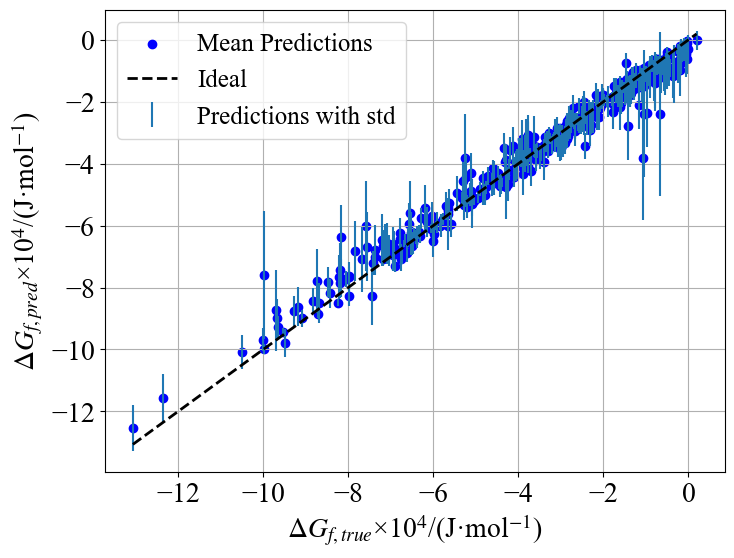

In [10]:
import matplotlib.ticker as ticker
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'  

predictions = []
for model in models:
    prediction = model.predict(df_train_allsites[FEATURES])
    predictions.append(prediction)

# 转换为 NumPy 数组
predictions = np.array(predictions)

# 计算预测均值和标准差
pred_mean = np.mean(predictions, axis=0)
pred_std = np.std(predictions, axis=0)

# 获取真实值
y_true = df_train_allsites[TARGET]

# 计算评估指标
mae = mean_absolute_error(y_true, pred_mean)
rmse = np.sqrt(mean_squared_error(y_true, pred_mean))
r2 = r2_score(y_true, pred_mean)

# 打印评估指标
print(f"Training Set MAE: {mae:.4f}")
print(f"Training Set RMSE: {rmse:.4f}")
print(f"Training Set R²: {r2:.4f}")

# 绘制误差图和散点图
plt.figure(figsize=(8, 6))

plt.errorbar(y_true, pred_mean, yerr=pred_std, linestyle="None", label="Predictions with std")
plt.scatter(y_true, pred_mean, color='blue', label="Mean Predictions")
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=2, label="Ideal")
plt.xlabel("$\Delta$$G_{f,true}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.ylabel("$\Delta$$G_{f,pred}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)

#plt.title("True vs Predicted Values (Training Set)", fontsize=20)
plt.legend(prop={'family': 'Times New Roman', 'size': 18})
plt.xticks(fontsize=20, fontfamily='Times New Roman')
plt.yticks(fontsize=20, fontfamily='Times New Roman')
ax = plt.gca()
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-2, 2))  # 指定指数范围
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.ticklabel_format(style='sci', axis='both', scilimits=(4, 4))
ax.xaxis.offsetText.set_fontsize(20)
ax.yaxis.offsetText.set_fontsize(20)
ax.xaxis.offsetText.set_fontfamily('Times New Roman')
ax.yaxis.offsetText.set_fontfamily('Times New Roman')
ax.get_xaxis().get_offset_text().set_visible(False)
ax.get_yaxis().get_offset_text().set_visible(False)

plt.grid(True)
plt.show()

# 调用模型在测试集上预测并评价性能

MAE: 5232.9019
RMSE: 7906.9480
R²: 0.9009


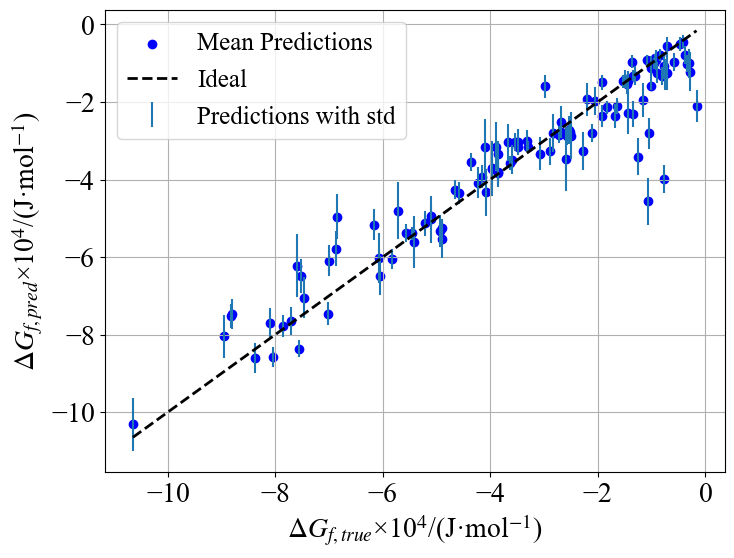

In [11]:
predictions_new = []
for model in models:
    prediction = model.predict(df_test_allsites[FEATURES])
    predictions_new.append(prediction)

# 转换为 NumPy 数组
predictions_new = np.array(predictions_new)

# 计算预测均值和标准差
pred_mean = np.mean(predictions_new, axis=0)
pred_std = np.std(predictions_new, axis=0)

# 获取真实值
y_true = df_test_allsites[TARGET]

# 计算评估指标
mae = mean_absolute_error(y_true, pred_mean)
rmse = np.sqrt(mean_squared_error(y_true, pred_mean))
r2 = r2_score(y_true, pred_mean)

# 打印评估指标
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

# 绘制误差图和散点图
plt.figure(figsize=(8, 6))
plt.errorbar(y_true, pred_mean, yerr=pred_std, linestyle="None", label="Predictions with std")
plt.scatter(y_true, pred_mean, color='blue', label="Mean Predictions")
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=2, label="Ideal")
plt.xlabel("$\Delta$$G_{f,true}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.ylabel("$\Delta$$G_{f,pred}$×10$^{4}$/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
#plt.title("True vs Predicted Values (Test Set)", fontsize=20)
plt.legend(prop={'family': 'Times New Roman', 'size': 18})
plt.xticks(fontsize=20, fontfamily='Times New Roman')
plt.yticks(fontsize=20, fontfamily='Times New Roman')
ax = plt.gca()
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-2, 2))  # 指定指数范围
ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.ticklabel_format(style='sci', axis='both', scilimits=(4, 4))
ax.xaxis.offsetText.set_fontsize(20)
ax.yaxis.offsetText.set_fontsize(20)
ax.xaxis.offsetText.set_fontfamily('Times New Roman')
ax.yaxis.offsetText.set_fontfamily('Times New Roman')
ax.get_xaxis().get_offset_text().set_visible(False)
ax.get_yaxis().get_offset_text().set_visible(False)
plt.grid(True)
plt.show()

# 计算SHapley Additive exPlanations贡献值用于特征向量降维

Top 20 Most Important Features and Their Average SHAP Values:
------------------------------------------------------------
1. Formation Energy per Atom (eV/atom): 6349.624512 ± 446.128815
2. Warren_Cowley_Order: 1604.742798 ± 460.972107
3. Electronegativity_Diff: 1089.825439 ± 139.721024
4. path_χ/Z_eff_min: 936.351379 ± 638.244385
5. circular_Z_eff_std: 788.515137 ± 132.279892
6. path_length_std: 755.400024 ± 275.351471
7. path_χ_max: 719.625854 ± 434.888031
8. circular_χ_std: 716.301025 ± 204.218155
9. circular_χ/Z_eff_min: 713.543701 ± 257.272095
10. path_group*ΔH_atom_max: 666.814331 ± 317.807190
11. path_IP1_std: 645.714966 ± 288.797974
12. path_C_std: 634.110901 ± 471.183472
13. circular_r_cov_std: 605.137573 ± 282.633026
14. circular_ΔH_vapor_max: 603.726135 ± 219.869232
15. circular_period/Z_eff_max: 592.997437 ± 334.826691
16. circular_χ/Z_eff_std: 591.352722 ± 348.606812
17. circular_r_vdW_std: 588.388062 ± 205.359863
18. circular_mass*C_min: 582.472168 ± 178.860947
19. circu

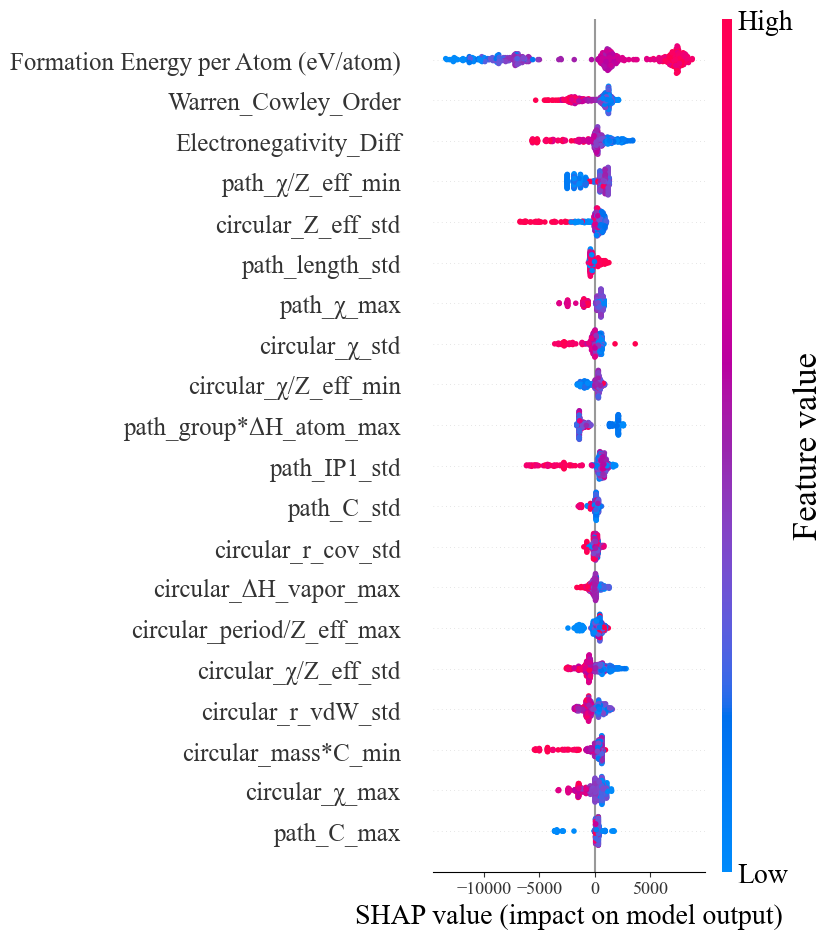

In [12]:
# 计算SHAP值（训练集）
shap_values_list = []
for model in models:
    # 提取Pipeline的前两个步骤（预处理）
    preprocessor = Pipeline(model.steps[:1])  # 'scaling' 
    # 转换测试集数据
    X_train_transformed = preprocessor.transform(df_train_allsites[FEATURES])
    # 提取XGBoost模型
    xgb_model_test = model.named_steps['xgb']
    # 计算SHAP值
    explainer = shap.TreeExplainer(xgb_model_test)
    shap_values = explainer.shap_values(X_train_transformed)
    shap_values_list.append(shap_values)


# 计算每个模型的特征重要性
feature_importances = []
for shap_values in shap_values_list:
    importance = np.mean(np.abs(shap_values), axis=0)
    feature_importances.append(importance)
 

# 计算所有模型的平均特征重要性和标准差
overall_importance = np.mean(feature_importances, axis=0)
importance_std = np.std(feature_importances, axis=0)

# 绘制平均特征重要性柱状图
"""
plt.figure(figsize=(10, 6))
plt.bar(FEATURES, overall_importance, yerr=importance_std, capsize=5)
plt.xlabel("特征")
plt.ylabel("平均 |SHAP值|")
plt.title("所有模型的平均特征重要性（带标准差）")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
"""
# 可选：绘制前N个重要特征（如果特征过多）
# 打印前20个最重要的特征名称和对应的SHAP值
top_n = 20
indices = np.argsort(overall_importance)[::-1][:top_n]  # 获取前20个特征的索引
print(f"Top {top_n} Most Important Features and Their Average SHAP Values:")
print("-" * 60)
for i, idx in enumerate(indices):
    feature_name = np.array(FEATURES)[idx]
    shap_value = overall_importance[idx]
    shap_std = importance_std[idx]
    print(f"{i+1}. {feature_name}: {shap_value:.6f} ± {shap_std:.6f}")
print("-" * 60)
"""
top_n = 20
indices = np.argsort(overall_importance)[::-1][:top_n]
plt.figure(figsize=(10, 6))
plt.barh(np.array(FEATURES)[indices], overall_importance[indices], xerr=importance_std[indices], capsize=5)
plt.ylabel("features")
plt.xlabel("average |SHAP value|")
plt.gca().invert_yaxis()  # 反转Y轴，使最重要的特征在顶部
plt.tight_layout()
plt.show()
"""

# 绘制第一个模型的SHAP摘要图
#shap.summary_plot(shap_values_list[0], df_train_allsites[FEATURES], show=True)
# Get indices of top features (up to the number of features available)
num_features = len(FEATURES)
max_display = min(20, num_features)  # Ensure max_display doesn't exceed number of features
top_indices = np.argsort(overall_importance)[::-1][:max_display]

# Create SHAP Explanation object (using first model's SHAP values)
shap_values = shap_values_list[0]
X_train_transformed = Pipeline(models[0].steps[:1]).transform(df_train_allsites[FEATURES])
explanation = shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=X_train_transformed,
    feature_names=np.array(FEATURES)
)

# Create beeswarm plot
shap.plots.beeswarm(
    explanation,
    max_display=max_display,
    order=np.argsort(overall_importance)[::-1],  # Sort by importance
    group_remaining_features=False,  # Avoid grouping issues
    show=False
)

ax = plt.gca()
# X-axis label (SHAP value)
ax.set_xlabel(ax.get_xlabel(), fontsize=20)
# Y-axis tick labels (feature names)
for label in ax.get_yticklabels():
    label.set_fontsize(18)
# X-axis tick labels
for label in ax.get_xticklabels():
    label.set_fontsize(13)

# Access color bar using Method 2 (figure axes)
cbar = None
fig = plt.gcf()
for cb in fig.get_axes():
    if isinstance(cb, plt.Axes) and cb.get_label().startswith('<colorbar'):
        cbar = cb
        print(f"Color bar found in figure axes: {cbar is not None}")
        break
else:
    print("Warning: Color bar not found in figure axes")

# Apply font size changes to color bar
if cbar is not None:
    try:
        # Set color bar label (use Chinese if feature names contain Chinese)
        label = '特征值' if any(u'\u4e00' <= c <= u'\u9fff' for c in ''.join(FEATURES)) else 'Feature value'
        cbar.set_ylabel(label, fontsize=25)  # Use set_ylabel for axes object
        # Set color bar tick labels
        cbar.tick_params(axis='y', labelsize=20)
        # Alternative: Directly set font size for all text objects
        for text in cbar.get_yticklabels():
            text.set_fontsize(20)
        # Debugging: Confirm settings
        print(f"Color bar label set to: {cbar.get_ylabel()}, fontsize: 20")
        print(f"Color bar tick labels: {[text.get_text() for text in cbar.get_yticklabels()]}, fontsize: 20")
    except Exception as e:
        print(f"Error modifying color bar: {e}")
else:
    print("Warning: Color bar not found, cannot apply font size changes")
# Adjust layout and display
plt.tight_layout()
plt.show()


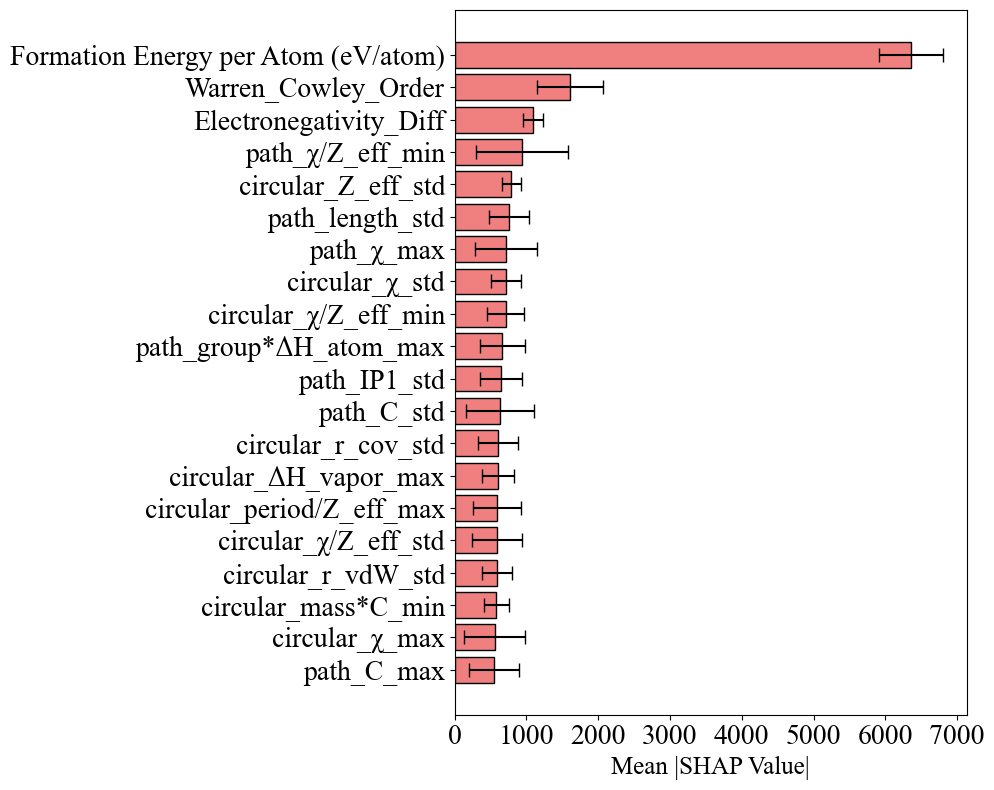

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# 假设数据：前20个特征的名称、SHAP贡献平均值和方差
features = ['Formation Energy per Atom (eV/atom)',	'Warren_Cowley_Order'	,'Electronegativity_Diff',	'path_χ/Z_eff_min','circular_Z_eff_std'	,'path_length_std',	'path_χ_max','circular_χ_std',	'circular_χ/Z_eff_min',	'path_group*ΔH_atom_max'	,'path_IP1_std',	'path_C_std','circular_r_cov_std','circular_ΔH_vapor_max',	'circular_period/Z_eff_max'	,'circular_χ/Z_eff_std'	,'circular_r_vdW_std','circular_mass*C_min',	'circular_χ_max'	,'path_C_max']  # 特征名称
shap_means = [6349.624512,	1604.742798,	1089.825439,	936.351379,	788.515137,	755.400024,	719.625854,	716.301025,	713.543701,	666.814331,	645.714966,	634.110901,	605.137573,	603.726135,	592.997437,	591.352722,	588.388062,	582.472168	,556.947632	,548.092163]  # SHAP贡献平均值
shap_variances = [446.128815,	460.972107,	139.721024,	638.244385,	132.279892,	275.351471,	434.888031,204.218155,	257.272095,	317.80719	,288.797974,	471.183472,	282.633026	,219.869232,	334.826691,	348.606812,	205.359863	,178.860947	,424.389038	,349.228088]  # 方差

# 计算标准差（误差条使用标准差，标准差是方差的平方根）


# 创建水平条形图
plt.figure(figsize=(10, 8))
plt.barh(features, shap_means, xerr=shap_variances, capsize=5, color='lightcoral', edgecolor='black')

# 设置图表标题和标签
#plt.title('SHAP Contribution Mean and Variance for Top 20 Features', fontsize=18)
plt.xlabel('Mean |SHAP Value|', fontsize=18)
plt.gca().invert_yaxis()
plt.xticks(fontsize=20, fontfamily='Times New Roman')
plt.yticks(fontsize=20, fontfamily='Times New Roman')
# 调整布局以防止标签被裁切
plt.tight_layout()


# 绘制训练集学习曲线(621个样本通过简单描述符训练)

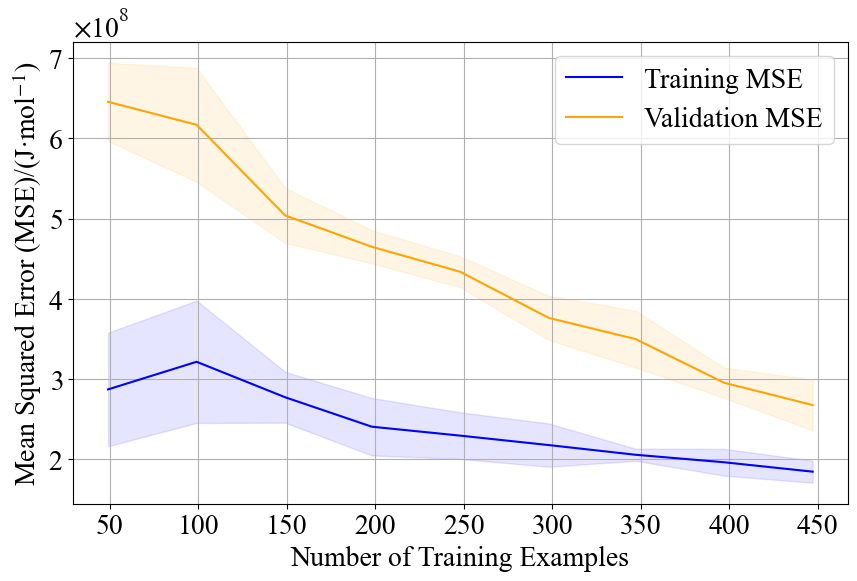

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import mean_squared_error

# 设置全局字体为 Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# 参数设置
N_ensemble = 10
train_sizes = np.linspace(0.1, 0.9, 9)
train_sizes_absolute = (train_sizes * len(df_train_allsites)).astype(int)

# 提取特征和目标值
X = df_train_allsites[FEATURES]
y = df_train_allsites[TARGET]

# 初始化存储结果的数组
train_scores = np.zeros((len(train_sizes), N_ensemble))
test_scores = np.zeros((len(train_sizes), N_ensemble))

# 每一个数据量都重新进行随机采样
for i, (train_size_float, train_size_int) in enumerate(zip(train_sizes, train_sizes_absolute)):
    # 单次划分训练和验证集
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=train_size_float, test_size=1.0-train_size_float, random_state=42
    )
    Xs = []
    for j in range(N_ensemble):
        X_sample = resample(
            pd.concat([X_train, y_train], axis=1),
            replace=True,
            n_samples=train_size_int,  
            random_state=j
        )
        Xs.append(X_sample)
    for j, X_sample in enumerate(Xs):
        model = xgb_model(xgb_hyperparams, X_sample, FEATURES, TARGET)
        y_train_pred = model.predict(X_train)
        train_scores[i, j] = mean_squared_error(y_train, y_train_pred)
        y_test_pred = model.predict(X_test)
        test_scores[i, j] = mean_squared_error(y_test, y_test_pred)

# 计算均值和标准差
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

# 绘制学习曲线
plt.figure(figsize=(10, 6))
plt.plot(train_sizes_absolute, train_scores_mean, label="Training MSE", color="blue")
plt.plot(train_sizes_absolute, test_scores_mean, label="Validation MSE", color="orange")
plt.fill_between(train_sizes_absolute,
                 train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std,
                 alpha=0.1, color="blue")
plt.fill_between(train_sizes_absolute,
                 test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std,
                 alpha=0.1, color="orange")
plt.xlabel("Number of Training Examples", fontfamily='Times New Roman', fontsize=20)
plt.ylabel("Mean Squared Error (MSE)/(J·mol$^{-1}$)", fontfamily='Times New Roman', fontsize=20)
plt.legend(loc="best", prop={'family': 'Times New Roman', 'size': 20})
ax = plt.gca()  # 获取当前坐标轴
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_visible(True)  # 确保偏移文本（1e8）可见
ax.yaxis.set_offset_position('left')  # 偏移文本位置
ax.yaxis.get_offset_text().set_fontfamily('Times New Roman')  # 设置偏移文本字体
ax.yaxis.get_offset_text().set_size(20)  # 设置偏移文本大小
ax.yaxis.get_offset_text().set_text(r'$\times 10^{8}$')  # 设置为 ×10^8
ax.tick_params(axis='both', which='major', labelsize=20, labelfontfamily='Times New Roman')
plt.grid(True)


# 绘制SHAP决策图观察异常样本(621个样本通过简单描述符训练)

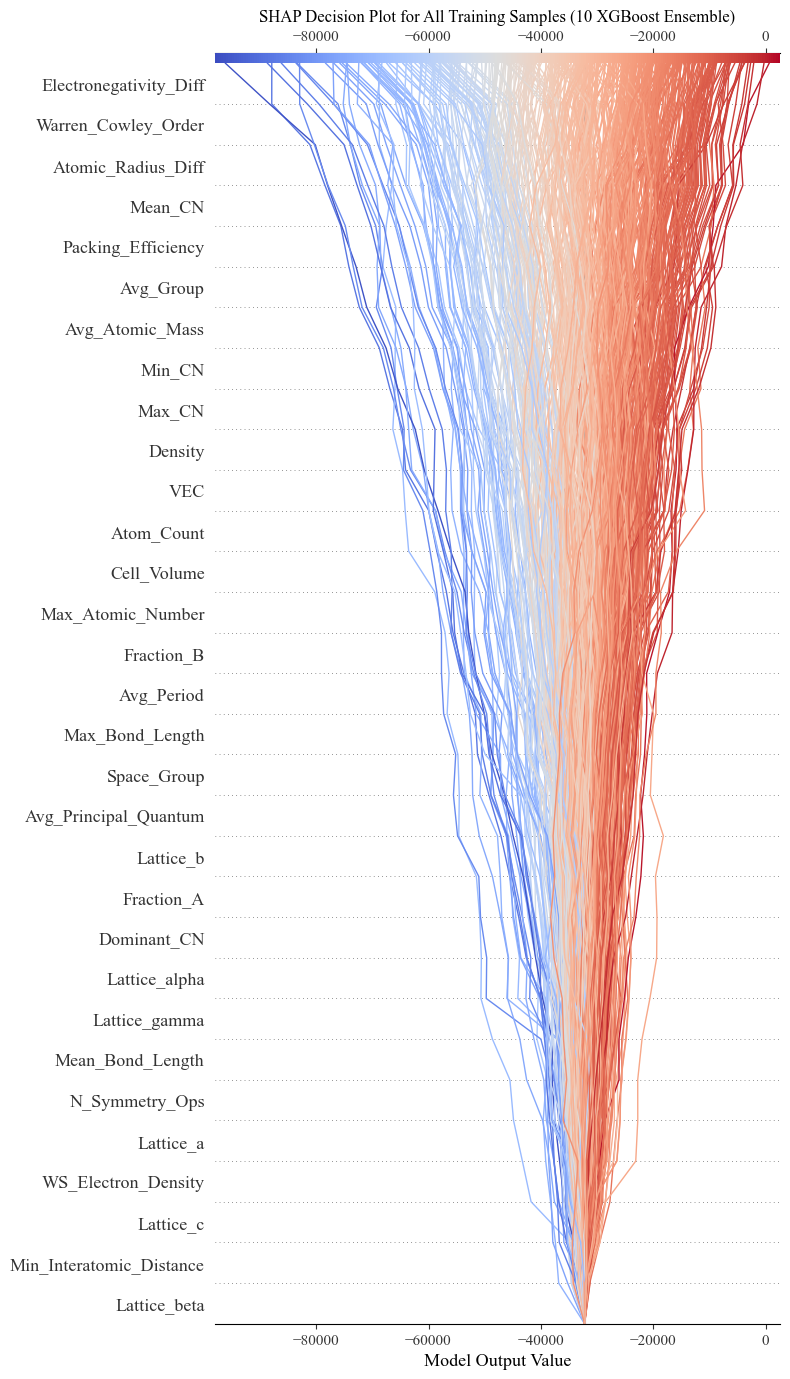

In [12]:
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

# Assuming `models`, `df_train_allsites`, and `FEATURES` are defined:
# - `models`: List of 10 Pipeline objects, each with a 'scaling' step and 'xgb' step
# - `df_train_allsites`: DataFrame with training data
# - `FEATURES`: List of feature column names

# Calculate SHAP values for each model
shap_values_list = []
for idx, model in enumerate(models):
    try:
        # Extract preprocessing steps (assuming 'scaling' is the first step)
        preprocessor = Pipeline(model.steps[:1])
        # Transform training data
        X_train_transformed = preprocessor.transform(df_train_allsites[FEATURES])
        # Extract XGBoost model
        xgb_model = model.named_steps['xgb']
        # Initialize SHAP TreeExplainer
        explainer = shap.TreeExplainer(xgb_model)
        # Calculate SHAP values
        shap_values = explainer.shap_values(X_train_transformed)
        shap_values_list.append(shap_values)
        # Store expected value (should be consistent across models)
        if idx == 0:
            expected_value = explainer.expected_value
    except Exception as e:
        print(f"Error processing model {idx}: {e}")
        continue

# Verify that SHAP values were computed
if not shap_values_list:
    raise ValueError("No SHAP values computed. Check model or data integrity.")

# Aggregate SHAP values across models (average for ensemble)
shap_values_ensemble = np.mean(shap_values_list, axis=0)  # Shape: (n_samples, n_features)

# Get feature data for plotting
features_all = df_train_allsites[FEATURES]

# Create SHAP decision plot for all training samples
plt.figure(figsize=(12, 8))
shap.decision_plot(
    expected_value,
    shap_values_ensemble,
    features_all,
    feature_names=FEATURES,
    show=False,  # Allow customization
    alpha=1,   # Reduce opacity for clarity with many samples
    plot_color="coolwarm",  # Use a clear color scheme
    feature_display_range=slice(0, len(FEATURES))
)
plt.gca().invert_yaxis()
# Customize plot
plt.title("SHAP Decision Plot for All Training Samples (10 XGBoost Ensemble)")
plt.xlabel("Model Output Value")
plt.tight_layout()
plt.savefig("shap_decision_plot_full_features_ensemble.png", dpi=300, bbox_inches="tight")

# 分析可能存在异常样本的特征向量中SHAP的异常值(621个样本通过简单描述符训练)

In [13]:
import pandas as pd
import numpy as np

# 设置你要分析的特征名
target_feature = "Avg_Principal_Quantum"

# 获取该特征的索引
feature_index = FEATURES.index(target_feature)

# 获取该特征在所有样本中的 SHAP 值
shap_column = shap_values_ensemble[:, feature_index]

# 创建分析用的 DataFrame
shap_df = pd.DataFrame({
    "sample_index": df_train_allsites.index,
    "feature_value": df_train_allsites[target_feature].values,
    "shap_value": shap_column,
    "Formula": df_train_allsites["Formula"].values,
    "MP_ID": df_train_allsites["MP_ID"].values
})

# 添加与中位数的偏离程度
shap_df["deviation"] = np.abs(shap_df["shap_value"] - shap_df["shap_value"].median())

# 按偏离程度排序
shap_df_sorted = shap_df.sort_values(by="deviation", ascending=False)

# 显示偏离最大的前10个样本
print(shap_df_sorted.head(10))


     sample_index  feature_value   shap_value Formula       MP_ID    deviation
313           395            6.0 -3679.096436    PrBi    mp-23171  3927.824707
92            115            6.0 -3372.646973   Ce2Bi  mp-1077367  3621.375244
125           159            6.0 -3248.250244  Pr5Bi3  mp-1105548  3496.978516
62             81            6.0 -3237.576660   αAuTm  mp-1017507  3486.304932
58             75            6.0 -3232.671631   αAuHo  mp-1007666  3481.399902
141           176            6.0 -3179.799316   βAuHo    mp-11245  3428.527588
51             66            6.0 -3152.964844   CeBi2     1927690  3401.693115
27             37            6.0 -3135.233154   PrBi2     1368767  3383.961426
450           562            6.0 -3095.701416    GdBi   mp-614481  3344.429688
319           404            6.0 -3081.050293  Pr4Bi3    mp-23314  3329.778564


# 预测金属间化合物相的形成吉布斯自由能

In [14]:
df_features = pd.read_csv("D:/毕设课题学习/毕设课题学习/毕设论文代码和数据集/数据集/模型准确性验证/features of DFT results.csv",encoding='gb2312')
df_features.head()

,Formula,MP_ID,Formation Energy per Atom (eV/atom),Energy per Atom (eV/atom),Total Magnetic Moment (μ_B),Electronegativity_Diff,Fraction_A,Fraction_B,Atomic_Radius_Diff,Max_Atomic_Number,...,T_E_bond_χ,T_E_bond_Z_eff,T_E_bond_ΔH_atom,T_E_bond_EA,T_E_bond_α_p,T_E_bond_r_vdW,T_E_bond_C,T_E_bond_ρ,T_E_bond_η,T_E_bond_Nv
0,Ni3Zn,mp-971758,-0.113473,-4.763512,1.484181e+00,0.26,0.750000,0.250000,2,30,...,4.002804,4.618620,4614.000921,17.797081,159.034466,61.581594,0.862142,27.188274,22.402783,30.790797
1,NiZn,mp-429,-0.254971,-3.774911,6.000000e-07,0.26,0.500000,0.500000,2,30,...,2.698248,3.113363,3110.249176,11.996824,107.203450,41.511501,0.581161,18.327327,15.101479,20.755750
2,Pd2Zn,mp-1103252,-0.317801,-4.517648,2.900000e-06,0.55,0.750000,0.250000,17,46,...,26.317527,119.625121,11780.681910,26.891727,599.561106,430.650435,6.794707,232.838335,38.743251,95.700097
3,Pd3Zn,mp-1187913,-0.462197,-4.335367,0.000000e+00,0.55,0.666667,0.333333,17,46,...,15.233098,69.241354,6818.888570,15.565456,347.037668,249.268875,3.932909,134.771372,22.425350,55.393083
4,PdZn,mp-1652,-0.576281,-3.796093,0.000000e+00,0.55,0.500000,0.500000,17,46,...,5.040594,22.911791,2256.353145,5.150571,114.833895,82.482446,1.301390,44.595509,7.420492,18.329433


In [15]:
df_predictions_300K=predict_G_ensemble_dataset(models=models, FEATURES=FEATURES, df_features=df_features, temperature=300)
print(df_predictions_300K)

[{'name': 'mp-971758', 'predicted_G_molar_300_mean': -14542.534, 'predicted_G_molar_300_std': 2542.09}, {'name': 'mp-429', 'predicted_G_molar_300_mean': -22891.154, 'predicted_G_molar_300_std': 4368.163}, {'name': 'mp-1103252', 'predicted_G_molar_300_mean': -35017.043, 'predicted_G_molar_300_std': 5383.09}, {'name': 'mp-1187913', 'predicted_G_molar_300_mean': -39804.31, 'predicted_G_molar_300_std': 4843.385}, {'name': 'mp-1652', 'predicted_G_molar_300_mean': -48062.418, 'predicted_G_molar_300_std': 5612.008}, {'name': 'mp-1215714', 'predicted_G_molar_300_mean': -42066.008, 'predicted_G_molar_300_std': 6467.1147}, {'name': 'mp-30856', 'predicted_G_molar_300_mean': -27958.332, 'predicted_G_molar_300_std': 4360.085}, {'name': 'mp-894', 'predicted_G_molar_300_mean': -44985.85, 'predicted_G_molar_300_std': 4951.8315}, {'name': 'mp-1380', 'predicted_G_molar_300_mean': -20188.957, 'predicted_G_molar_300_std': 2311.146}]


# 模型可解释性

## 局部依赖图

Color bar found in figure axes: True
Color bar label set to: Formation Energy per Atom (eV/atom), fontsize: 20
Color bar tick labels: ['−1.0', '−0.8', '−0.6', '−0.4', '−0.2', '0.0', '0.2'], fontsize: 20


<Figure size 1000x600 with 0 Axes>

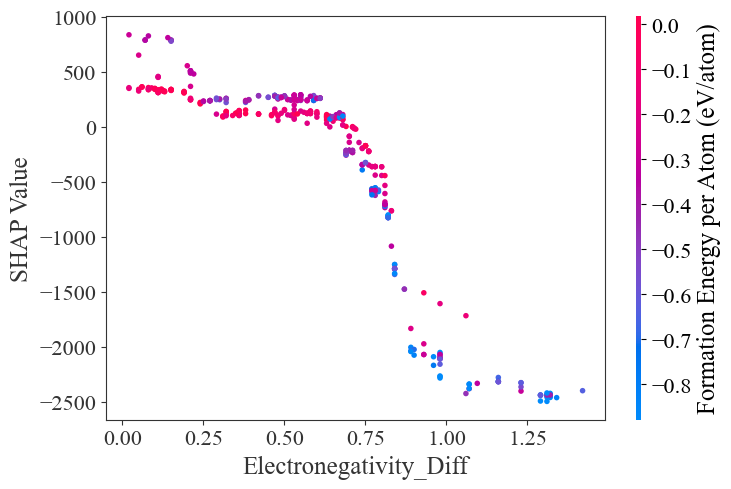

In [16]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

def plot_shap_dependence_all(feature_name, X_train_filtered, models, FEATURES, pipeline=True, interaction_feature=None, 
                            x_lim=None, y_lim=None, title_fontsize=16, label_fontsize=14, tick_fontsize=12):
    """
    为验证集所有样本绘制SHAP依赖图，分析指定特征的贡献
    Args:
        feature_name: Feature to analyze (e.g., 'Formation Energy per Atom (eV/atom)')
        X_train_filtered: Validation set DataFrame
        models: List of trained models (Pipeline or XGBoost)
        FEATURES: List of feature column names
        pipeline: Whether models are Pipeline objects (True to extract XGBoost model)
        interaction_feature: Optional feature for coloring the dependence plot to show interactions
        x_lim: Tuple of (xmin, xmax) to set x-axis limits (optional)
        y_lim: Tuple of (ymin, ymax) to set y-axis limits (optional)
        title_fontsize: Font size for plot title (default: 16)
        label_fontsize: Font size for axis labels (default: 14)
        tick_fontsize: Font size for axis tick labels (default: 12)
    """
    # Validate inputs
    if feature_name not in FEATURES:
        print(f"Error: Feature '{feature_name}' not found in FEATURES")
        return
    if interaction_feature and interaction_feature not in FEATURES:
        print(f"Error: Interaction feature '{interaction_feature}' not found in FEATURES")
        return

    # Prepare samples
    samples_df = X_train_filtered[FEATURES]
    if samples_df.empty:
        print("Error: X_train_filtered is empty")
        return

    # Initialize SHAP values
    shap_values_list = []

    # Compute SHAP values for each model
    for model in models:
        if pipeline:
            xgb_model = model.named_steps['xgb']  # Extract XGBoost from Pipeline
        else:
            xgb_model = model

        # Create TreeExplainer
        explainer = shap.TreeExplainer(xgb_model)

        # Compute SHAP values for all samples
        shap_values = explainer.shap_values(samples_df)
        shap_values_list.append(shap_values)

    # Average SHAP values across models
    shap_values_array = np.mean(shap_values_list, axis=0)  # Shape: (n_samples, n_features)

    # Plot SHAP dependence plot
    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        feature_name,
        shap_values_array,
        samples_df,
        feature_names=FEATURES,
        interaction_index=interaction_feature,  # None or feature name for coloring
        show=False
    )
    
    # Customize axis limits
    if x_lim is not None:
        plt.xlim(x_lim)
    if y_lim is not None:
        plt.ylim(y_lim)
    
    # Customize font sizes
    ax = plt.gca()
    ax.set_xlabel(feature_name, fontsize=label_fontsize)
    ax.set_ylabel("SHAP Value", fontsize=label_fontsize)

    
    # Customize tick label font size
    ax.tick_params(axis='both', which='major', labelsize=tick_fontsize)
    
    # Customize spines
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

    cbar = None
    fig = plt.gcf()
    for cb in fig.get_axes():
        if isinstance(cb, plt.Axes) and cb.get_label().startswith('<colorbar'):
            cbar = cb
            print(f"Color bar found in figure axes: {cbar is not None}")
            break
    else:
        print("Warning: Color bar not found in figure axes")
    
    # Apply font size changes to color bar
    if cbar is not None:
        try:
            # Set color bar label (use Chinese if feature names contain Chinese)
            label = '特征值' if any(u'\u4e00' <= c <= u'\u9fff' for c in ''.join(FEATURES)) else interaction_feature
            cbar.set_ylabel(label, fontsize=18)  # Use set_ylabel for axes object
            # Set color bar tick labels
            cbar.tick_params(axis='y', labelsize=16)
            # Alternative: Directly set font size for all text objects
            for text in cbar.get_yticklabels():
                text.set_fontsize(16)
            # Debugging: Confirm settings
            print(f"Color bar label set to: {cbar.get_ylabel()}, fontsize: 20")
            print(f"Color bar tick labels: {[text.get_text() for text in cbar.get_yticklabels()]}, fontsize: 20")
        except Exception as e:
            print(f"Error modifying color bar: {e}")
    else:
        print("Warning: Color bar not found, cannot apply font size changes")
    plt.tight_layout()
    plt.show()

# Example call
plot_shap_dependence_all(
    feature_name='Electronegativity_Diff',
    X_train_filtered=df_train_allsites,
    models=models,
    FEATURES=FEATURES,
    pipeline=True,
    interaction_feature='Formation Energy per Atom (eV/atom)',  # Optional: set to None or another feature Electronegativity_Diff
    #x_lim=(-1.8, 1.5),  # Set x-axis limits
    #y_lim=(-3000, 3000),  # Set y-axis limits
    title_fontsize=18,  # Adjust title font size
    label_fontsize=18,  # Adjust axis label font size
    tick_fontsize=16    # Adjust tick label font size
)